# IMAGO | RGB — Resources in Green and Built environments

**Data:** [IMAGO RGB (2024)](https://data.imago.ac.uk/)

**Goal:** Explore the IMAGO RGB product and understand how greenspace availability varies across small statistical areas.

> **Getting the data**
>
> Download the RGB dataset from the IMAGO Data Catalogue and place the GeoPackage inside the `data/rgb/` directory.
>
> The product provides small-area statistics derived from a binary classification of green and non-green pixels. This tutorial focuses on the `greenspace_ratio` variable, which represents the proportion of valid pixels classified as green within each area.

## What is RGB?

The IMAGO RGB  product identifies green and non-green pixels across the United Kingdom, from satellite imagery and summarises this information within Lower Layer Super Output Areas (LSOAs).

The resulting dataset provides area-level greenspace statistics rather than individual pixel-level classifications.

## The Reason for the Data

Greenspace is an important environmental characteristic associated with health, well-being, urban cooling and climate adaptation.

Providing greenspace indicators at small-area level allows researchers to examine geographical variation in green cover and integrate this information with demographic, socioeconomic and environmental datasets.

## Installing Libraries

In [1]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

## Loading the Dataset

The dataset provides greenspace statistics
for small statistical areas across the United Kingdom.
The GeoPackage contains both the geographical boundaries
and associated greenspace indicators.

First, load the dataset and inspect its structure.

In [2]:
data_dir = Path("../data/rgb")
if not data_dir.exists():
    data_dir = Path("data/rgb")
gpkg_path = data_dir / "greenspace_lsoa.gpkg"
if not gpkg_path.exists():
    raise FileNotFoundError(gpkg_path.resolve())
greens = gpd.read_file(gpkg_path)
greens.head()

,data_zone_code,greenspace_area,greenspace_ratio,greenspace_rank,nodata_ratio,geometry
0,E01027477,143383500.0,0.9719,46,0.0,"MULTIPOLYGON (((385765.509 560476.073, 386122...."
1,E01027505,119446000.0,0.9685,85,0.0,"MULTIPOLYGON (((395325.889 561863.699, 395494...."
2,E01020864,85209200.0,0.9654,127,0.0,"MULTIPOLYGON (((411535.295 534875.166, 411695...."
3,E01020889,99911100.0,0.9620,179,0.0,"MULTIPOLYGON (((382597.5 544573.875, 382820.15..."
4,E01027447,176267400.0,0.9619,182,0.0,"MULTIPOLYGON (((412089.281 593467.375, 412451...."


> **Note:** The RGB product covers the UK.
> For this tutorial, we use North East England as an
> illustrative study area. The same workflow can be
> applied to other geographical areas.

## Exploring the Dataset

The principal variables available in the RGB dataset are:

- `data_zone_code`: Unique small-area identifier.
- `greenspace_area`: Area classified as green (m²).
- `greenspace_ratio`: Proportion of valid pixels classified as green (0–1).
- `greenspace_rank`: National greenspace rank supplied with the product.
- `nodata_ratio`: Estimated proportion of the area without valid imagery (0–1).
- `geometry`: Small-area boundary geometry.

For this tutorial, we focus on `greenspace_ratio`.

Before proceeding, we check the number of geographical areas,
the coordinate reference system and whether the selected
indicator contains any missing values.

In [3]:
print("Number of LSOAs:", len(greens))
print("CRS:", greens.crs)
print("Missing greenspace ratios:", greens["greenspace_ratio"].isna().sum())

Number of LSOAs: 1257
CRS: EPSG:27700
Missing greenspace ratios: 0


## Analysing the Dataset

The `greenspace_ratio` variable expresses green cover as a
proportion between 0 and 1. To make the values easier to
interpret, we convert this proportion into a percentage
by multiplying it by 100.

We then calculate summary statistics to understand the
range and variation of greenspace across the selected
study area. Invalid ratios and areas without valid imagery
are excluded.

In [4]:
valid = greens["greenspace_ratio"].between(0, 1) & greens["nodata_ratio"].between(0, 1, inclusive="left")
greens["greenspace_pct"] = greens["greenspace_ratio"].where(valid) * 100
greens[["greenspace_pct"]].describe().round(2)

,greenspace_pct
count,1257.00
mean,44.75
std,25.02
min,0.00
25%,25.54
50%,40.26
75%,62.88
max,97.19


> **Note:** Across the 1,257 LSOAs in North East England,
> the mean greenspace percentage is 44.75%, with a median
> of 40.26%. Values range from 0% to 97.19%, indicating
> considerable variation in green cover between areas.
> The mean represents an unweighted average across LSOAs,
> rather than the percentage of the entire region
> classified as green.

### Distribution of greenspace

A histogram shows how frequently different levels of green cover occur across the study area.

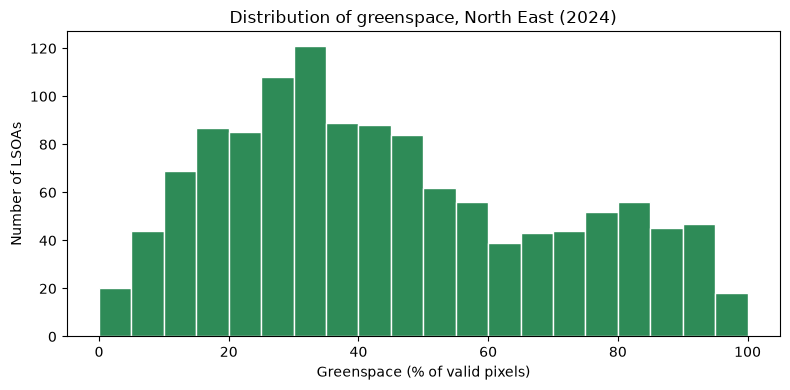

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(greens["greenspace_pct"].dropna(), bins=20, range=(0, 100), color="seagreen", edgecolor="white")
ax.set(xlabel="Greenspace (% of valid pixels)", ylabel="Number of LSOAs", title="Distribution of greenspace, North East (2024)")
plt.tight_layout()
plt.show()

> **Note:** The distribution shows considerable variation in
> greenspace across North East England. A greater concentration
> of LSOAs is observed between 15% and 50% green cover, with
> the most frequent interval at 30–35%. A smaller but noticeable
> concentration is also observed between 70% and 95%, while
> very low and very high greenspace percentages are less common.

## Visualising the dataset

Plot the greenspace percentage for each LSOA using a fixed scale from 0 to 100%. Darker green represents a greater proportion of valid pixels classified as green.

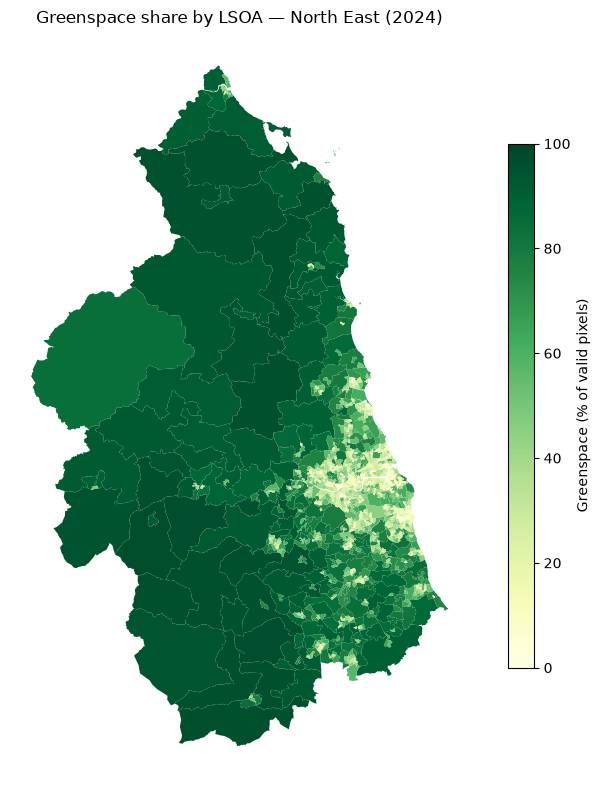

In [6]:
fig, ax = plt.subplots(figsize=(8, 8))
greens.plot(column="greenspace_pct", cmap="YlGn", vmin=0, vmax=100, legend=True, ax=ax, linewidth=0, missing_kwds={"color":"lightgrey"}, legend_kwds={"label":"Greenspace (% of valid pixels)", "shrink":0.7})
ax.set_title("Greenspace share by LSOA — North East (2024)")
ax.set_axis_off()
plt.tight_layout()
plt.show()

> **Note:** Higher greenspace percentages are widespread in the western and northern parts of the study area, while lower percentages are concentrated in parts of the eastern urban corridor. These patterns describe green cover, not vegetation type or accessibility.

## What have we learnt?

We have loaded the RGB dataset, understood its variables, converted green cover to percentages and explored its statistical and spatial distribution.

The supplied case study has generally complete imagery coverage: the mean estimated missing coverage is approximately 0.02% across LSOAs. Users should check `nodata_ratio` when applying this workflow to other datasets or study areas.

## Further exploration

How might green cover relate to temperature, population or deprivation? The same workflow provides a starting point for independent research using compatible geographical units.

## Data documentation
- Accompanying `greenspace_lsoa_structural_metadata.json`.
- [IMAGO Data Catalogue](https://data.imago.ac.uk/) — direct product link.